# SR-VAE: test a trained model on every signal level (BioSR)

Stand-alone notebook: it needs only **the saved model file** and **the test folder**. No training data, no training code.

```
my_test_project/
├── srvae_test_by_level.ipynb     <- this notebook
├── best.pt                       <- the saved model (best.pt, last.pt or any ckpt_epNNN.pt)
└── test/                         <- any location, set TEST_ROOT below
    ├── test_gt/    001.tif ... 015.tif
    └── test_wf/    <level folder 1> ... <level folder 10>, each with 001.tif ... 015.tif
```

For every level folder the model super-resolves the widefield images and is compared against the same `test_gt` images
(PSNR and SSIM, with bicubic as the baseline). The model classes below must be the **same architecture** that was trained.

## 1. Imports

In [17]:
# !pip install torch numpy scikit-image mrcfile tifffile matplotlib
import glob, math, os, re
from types import SimpleNamespace

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

## 2. Image reading, normalisation and lazy pairing

In [18]:
def read_stack(path):
    """Read .mrc / .tif / .npy into a float32 numpy array."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".mrc", ".rec", ".st"):
        import mrcfile
        with mrcfile.open(path, permissive=True) as m:
            return np.array(m.data, dtype=np.float32)
    if ext in (".tif", ".tiff"):
        import tifffile
        return tifffile.imread(path).astype(np.float32)
    if ext == ".npy":
        return np.load(path).astype(np.float32)
    if ext in (".png", ".jpg", ".jpeg", ".bmp"):
        from skimage import io
        a = io.imread(path).astype(np.float32)
        return a[..., :3].mean(axis=-1) if a.ndim == 3 else a      # RGB -> gray
    raise ValueError(f"Unsupported file type: {path}")


def percentile_norm(img, lo=0.03, hi=99.7):
    """Robust intensity normalisation to [0,1]:  x' = clip((x - p_lo) / (p_hi - p_lo), 0, 1)."""
    a, b = np.percentile(img, [lo, hi])
    return np.clip((img - a) / (b - a + 1e-8), 0.0, 1.0).astype(np.float32)


IMG_EXTS = (".tif", ".tiff", ".png", ".mrc", ".npy")


def list_images(folder):
    return sorted(f for f in glob.glob(os.path.join(folder, "*")) if f.lower().endswith(IMG_EXTS))

In [19]:
class LazyPairs:
    """
    List-like object of (widefield, SIM) pairs. Stores file paths only.
        pairs[i]      -> reads both files, averages frames if needed, percentile-normalises, returns (lr, hr)
        pairs[a:b]    -> list of loaded pairs (used by evaluate(), which does pairs[:max_images])
        len(pairs)    -> number of pairs
    random.choice(pairs) (used by PatchDataset) therefore triggers the disk read inside the DataLoader.
    """

    def __init__(self, wf_dir, gt_dir):
        wf, gt = list_images(wf_dir), list_images(gt_dir)
        if not wf or not gt:
            raise RuntimeError(f"No images found in {wf_dir} or {gt_dir}")
        stem = lambda p: os.path.splitext(os.path.basename(p))[0]
        gt_by_stem = {stem(p): p for p in gt}
        self.files = [(p, gt_by_stem[stem(p)]) for p in wf if stem(p) in gt_by_stem]
        if not self.files:
            print(f"[warn] no matching file names in {wf_dir} / {gt_dir}; pairing by sorted order")
            self.files = list(zip(wf, gt))

    def __len__(self):
        return len(self.files)

    def _load(self, i):
        lp, hp = self.files[i]
        lr = read_stack(lp)
        while lr.ndim > 2:                 # stack of raw frames -> widefield average
            lr = lr.mean(axis=0)
        hr = read_stack(hp)
        while hr.ndim > 2:                 # first frame of the SIM stack
            hr = hr[0]
        return percentile_norm(lr), percentile_norm(hr)

    def __getitem__(self, i):
        if isinstance(i, slice):
            return [self._load(j) for j in range(*i.indices(len(self)))]
        return self._load(i)

    def __iter__(self):
        return (self._load(j) for j in range(len(self)))

## 3. Model classes (same as in training)

In [20]:
class EnhancedUBP(nn.Module):
    """
    Enhanced Up-sampling Back-Projection block (Fig. 4b), 2x per block.
    Back-projection idea (DBPN): up-project, down-project back, and use the LR-space
    error to correct the HR estimate.
        h0 = PReLU( Deconv(x) )                 # HR estimate            (H -> 2H)
        l0 = Conv(h0)                           # project back to LR     (2H -> H)
        r  = l0 - x                             # LR-space residual
        h1 = Deconv( Conv1x1_a(r) )             # residual mapped to HR (1x1 conv = weighted shortcut)
        y  = h0 + Conv1x1_b(h1)                 # weighted addition = residual update
    Paper: 6x6 kernels, stride 2 (pad 2 -> exact 2x), 1x1 convs for weighting, and one
    activation after the first deconv only (the second one was removed as redundant).
    (The exact wiring of the two 1x1 convs is our reading of Fig. 4b.)
    """

    def __init__(self, nf):
        super().__init__()
        self.up1 = nn.ConvTranspose2d(nf, nf, 6, 2, 2)
        self.act = nn.PReLU(nf)
        self.down = nn.Conv2d(nf, nf, 6, 2, 2)
        self.res_1x1 = nn.Conv2d(nf, nf, 1)
        self.up2 = nn.ConvTranspose2d(nf, nf, 6, 2, 2)
        self.out_1x1 = nn.Conv2d(nf, nf, 1)

    def forward(self, x):
        h0 = self.act(self.up1(x))
        r = self.down(h0) - x
        h1 = self.up2(self.res_1x1(r))
        return h0 + self.out_1x1(h1)

In [21]:
class LRHREncoder(nn.Module):
    """
    Q(z | X, Y): outputs mu(X,Y) and log sigma^2(X,Y) (Fig. 2, "LR-HR Encoder").
    Two conv branches (one for Y, one for the bicubic-upsampled X) are fused with an
    element-wise sum, then FC layers give the k-dim mean and log-variance.
    Predicting log(sigma^2) instead of sigma^2 keeps the variance positive:
        sigma = exp(0.5 * logvar)
    """

    def __init__(self, patch_hr=128, z_dim=256, fc_hidden=2048, chs=(32, 64, 128, 256, 256)):
        super().__init__()
        assert patch_hr % 32 == 0, "HR patch must be divisible by 32 (5 stride-2 convs)"

        def branch():
            layers, c = [], 1
            for co in chs:
                layers += [nn.Conv2d(c, co, 3, 2, 1), nn.ReLU(inplace=True)]
                c = co
            return nn.Sequential(*layers)

        self.hr_branch, self.lr_branch = branch(), branch()
        flat = chs[-1] * (patch_hr // 32) ** 2
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(flat, fc_hidden), nn.ReLU(inplace=True),
                                nn.Linear(fc_hidden, fc_hidden), nn.ReLU(inplace=True))
        self.mu = nn.Linear(fc_hidden, z_dim)
        self.logvar = nn.Linear(fc_hidden, z_dim)

    def forward(self, hr, lr_up):
        f = self.fc(self.hr_branch(hr) + self.lr_branch(lr_up))     # (+) fusion, Fig. 2
        return self.mu(f), self.logvar(f).clamp(-10.0, 10.0)

In [22]:
class ConditionalSamplingGenerator(nn.Module):
    """
    G(X): conditional sampling generator (Sec. III-C, Fig. 5).
    Instead of drawing eps ~ N(0, I) in the reparameterisation trick, the noise is a learned,
    LR-conditioned vector that is normalised to zero mean / unit variance:
        g = Normalize( FC( ReLU( FC( Normalize(X) ) ) ) )
    Because g has zero mean and unit variance, it is a valid stand-in for eps, but it now
    carries information about X (the "low-frequency components" argument of the paper).
    """

    def __init__(self, z_dim=256, in_size=32, hidden=1024):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(in_size)      # makes G independent of the LR size
        self.fc1 = nn.Linear(in_size * in_size, hidden)
        self.fc2 = nn.Linear(hidden, z_dim)

    @staticmethod
    def _norm(v, eps=1e-6):
        return (v - v.mean(1, keepdim=True)) / (v.std(1, keepdim=True) + eps)

    def forward(self, lr):
        x = self._norm(self.pool(lr).flatten(1))       # centre LR to mean 0, var 1
        return self._norm(self.fc2(F.relu(self.fc1(x))))

In [23]:
class SRDecoder(nn.Module):
    """
    P(Y | z, X): SR decoder (Fig. 2 / Fig. 8).
        latent path : z -> FC -> FC -> reshape -> resize to LR size -> conv
        LR path     : X -> conv stack (LR resolution)
        fuse        : element-wise addition ("Addition" block, keeps SR close to the LR image)
        upsample    : log2(scale) enhanced UBP blocks (gradual 2x steps)
        output      : Y' = Conv(features) + Bicubic(X)         (global residual, "X'" in Fig. 2)
    """

    def __init__(self, z_dim=256, nf=64, scale=2, fc_hidden=2048, lat_ch=16, lat_hw=16):
        super().__init__()
        assert scale in (2, 4, 8), "scale must be a power of two"
        self.scale, self.lat_ch, self.lat_hw = scale, lat_ch, lat_hw
        self.fc = nn.Sequential(nn.Linear(z_dim, fc_hidden), nn.PReLU(),
                                nn.Linear(fc_hidden, lat_ch * lat_hw * lat_hw), nn.PReLU())
        self.lat_conv = nn.Sequential(nn.Conv2d(lat_ch, nf, 3, 1, 1), nn.PReLU(nf))
        self.lr_branch = nn.Sequential(nn.Conv2d(1, nf // 2, 3, 1, 1), nn.PReLU(nf // 2),
                                       nn.Conv2d(nf // 2, nf, 3, 1, 1), nn.PReLU(nf),
                                       nn.Conv2d(nf, nf, 3, 1, 1), nn.PReLU(nf))
        self.ubps = nn.Sequential(*[EnhancedUBP(nf) for _ in range(int(math.log2(scale)))])
        self.tail = nn.Conv2d(nf, 1, 3, 1, 1)

    def forward(self, z, lr):
        f_lr = self.lr_branch(lr)
        lat = self.fc(z).view(z.size(0), self.lat_ch, self.lat_hw, self.lat_hw)
        lat = F.interpolate(lat, size=f_lr.shape[-2:], mode="bilinear", align_corners=False)
        x = f_lr + self.lat_conv(lat)
        x = self.tail(self.ubps(x))
        return x + F.interpolate(lr, scale_factor=self.scale, mode="bicubic", align_corners=False)

In [24]:
class SRVAE(nn.Module):
    """
    Full SR-VAE.
    Training (needs Y):
        (mu, logvar) = Enc(Y, Bicubic(X))
        z  = mu + sigma * G(X),        sigma = exp(0.5 logvar)      # conditional reparam. trick
        Y' = Dec(z, X)
      (the standard trick is z = mu + sigma * eps, eps ~ N(0, I); Eq. 8-9, 10-11)
    Testing (Y not available, encoder is discarded, Fig. 8):
        z  = G(X)        # equals mu=0, sigma=1 (the prior) once KL -> 0
        Y' = Dec(z, X)
    """

    def __init__(self, scale=2, patch_lr=64, z_dim=256, nf=64, fc_hidden=2048):
        super().__init__()
        self.scale = scale
        self.enc = LRHREncoder(patch_lr * scale, z_dim, fc_hidden)
        self.gen = ConditionalSamplingGenerator(z_dim)
        self.dec = SRDecoder(z_dim, nf, scale, fc_hidden)

    def forward(self, lr, hr=None):
        g = self.gen(lr)
        if hr is None:
            return self.dec(g, lr), None, None
        lr_up = F.interpolate(lr, scale_factor=self.scale, mode="bicubic", align_corners=False)
        mu, logvar = self.enc(hr, lr_up)
        z = mu + torch.exp(0.5 * logvar) * g
        return self.dec(z, lr), mu, logvar

In [25]:
def build_model(a):
    return SRVAE(a.scale, a.lr_patch, a.z_dim, a.nf, a.fc_hidden)

## 4. Tiled inference and metrics (PSNR, SSIM)

In [26]:
@torch.no_grad()
def sr_full(model, lr, tile=64, overlap=8, bs=32):
    """
    Tiled full-image SR. lr: tensor (1,1,H,W) in [0,1].
    Each tile is (tile x tile); only the central (tile - 2*overlap) region is kept, so border
    artefacts of the decoder are discarded. Test-time path: z = G(X), no encoder.
    """
    s, dev = model.scale, lr.device
    _, _, H, W = lr.shape
    stride = tile - 2 * overlap
    nH, nW = math.ceil(H / stride), math.ceil(W / stride)
    x = F.pad(lr, (overlap,) * 4, mode="reflect")
    x = F.pad(x, (0, nW * stride + 2 * overlap - x.shape[3], 0, nH * stride + 2 * overlap - x.shape[2]),
              mode="reflect")
    out = torch.zeros(1, 1, nH * stride * s, nW * stride * s, device=dev)
    jobs = [(i, j) for i in range(nH) for j in range(nW)]
    for k in range(0, len(jobs), bs):
        chunk = jobs[k:k + bs]
        batch = torch.cat([x[:, :, i * stride:i * stride + tile, j * stride:j * stride + tile]
                           for i, j in chunk], 0)
        sr, _, _ = model(batch)
        core = sr[:, :, overlap * s:(tile - overlap) * s, overlap * s:(tile - overlap) * s]
        for n, (i, j) in enumerate(chunk):
            out[:, :, i * stride * s:(i + 1) * stride * s, j * stride * s:(j + 1) * stride * s] = core[n]
    return out[:, :, :H * s, :W * s].clamp(0, 1)


def psnr(a, b):
    """PSNR = 10 * log10( MAX^2 / MSE ), MAX = 1 for images in [0,1]."""
    mse = float(np.mean((a - b) ** 2))
    return 10.0 * math.log10(1.0 / max(mse, 1e-12))


def ssim(a, b):
    from skimage.metrics import structural_similarity
    return float(structural_similarity(a, b, data_range=1.0))


def evaluate(model, pairs, device, tile, overlap, max_images=None):
    model.eval()
    res = {"psnr": [], "ssim": [], "bic_psnr": [], "bic_ssim": []}
    for lr, hr in pairs[:max_images]:
        lr_t = torch.from_numpy(lr)[None, None].to(device)
        sr = sr_full(model, lr_t, tile, overlap)[0, 0].cpu().numpy()
        bic = F.interpolate(lr_t, scale_factor=model.scale, mode="bicubic",
                            align_corners=False).clamp(0, 1)[0, 0].cpu().numpy()
        res["psnr"].append(psnr(sr, hr)); res["ssim"].append(ssim(sr, hr))
        res["bic_psnr"].append(psnr(bic, hr)); res["bic_ssim"].append(ssim(bic, hr))
    return {k: float(np.mean(v)) for k, v in res.items()}

## 5. Settings: edit these three lines

In [27]:
TEST_ROOT = r"C:\Users\BITPATNA\Desktop\test_project\CCPs-2x-Test"        # folder that contains test_gt and test_wf
CKPT = "best.pt"                          # saved model file (best.pt / last.pt / ckpt_epNNN.pt)
TILE, OVERLAP = 64, 8                     # tiled inference, same as training

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)

device: cpu


## 6. Load the model

In [28]:
ck = torch.load(CKPT, map_location=dev, weights_only=False)
model = build_model(SimpleNamespace(**ck["args"])).to(dev)     # architecture settings stored in the checkpoint
model.load_state_dict(ck["model"])
model.eval()
print(f"loaded {CKPT} (epoch {ck['epoch']}, scale {model.scale}x)")

loaded best.pt (epoch 40, scale 2x)


## 7. Test every level

levels found: ['level_01', 'level_02', 'level_03', 'level_04', 'level_05', 'level_06', 'level_07', 'level_08', 'level_09']
level_01        n=15 | SR-VAE PSNR 23.60 SSIM 0.836 | bicubic PSNR 12.23 SSIM 0.043
level_02        n=15 | SR-VAE PSNR 24.23 SSIM 0.898 | bicubic PSNR 16.40 SSIM 0.067
level_03        n=15 | SR-VAE PSNR 24.33 SSIM 0.898 | bicubic PSNR 17.49 SSIM 0.093
level_04        n=15 | SR-VAE PSNR 24.44 SSIM 0.900 | bicubic PSNR 17.85 SSIM 0.119
level_05        n=15 | SR-VAE PSNR 24.46 SSIM 0.901 | bicubic PSNR 18.02 SSIM 0.141
level_06        n=15 | SR-VAE PSNR 24.43 SSIM 0.900 | bicubic PSNR 18.21 SSIM 0.171
level_07        n=15 | SR-VAE PSNR 24.63 SSIM 0.904 | bicubic PSNR 18.25 SSIM 0.193
level_08        n=15 | SR-VAE PSNR 24.91 SSIM 0.909 | bicubic PSNR 18.20 SSIM 0.201
level_09        n=15 | SR-VAE PSNR 25.28 SSIM 0.914 | bicubic PSNR 17.97 SSIM 0.200


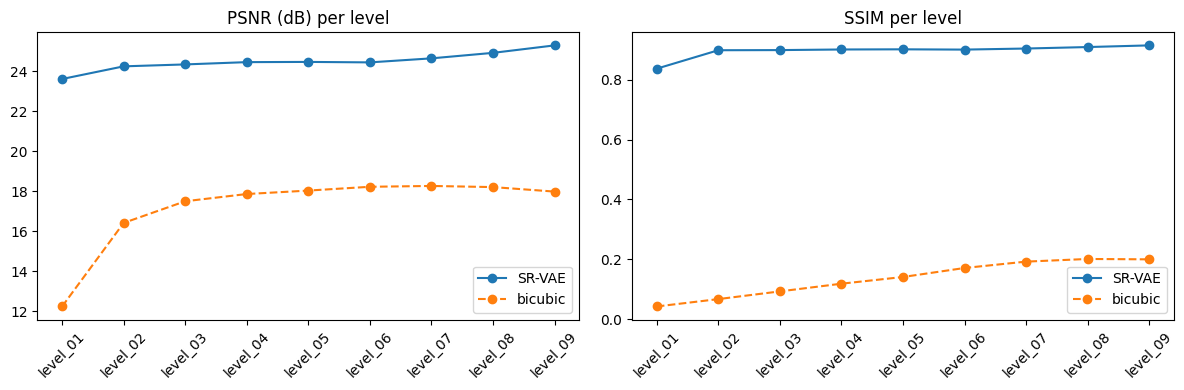

saved results_by_level.csv


In [29]:
# ---- find the level folders, in natural order (1, 2, ..., 10 - not 1, 10, 2) --------------------
gt_dir = os.path.join(TEST_ROOT, "test_gt")
wf_root = os.path.join(TEST_ROOT, "test_wf")
natural = lambda s: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", s)]
levels = sorted((d for d in os.listdir(wf_root) if os.path.isdir(os.path.join(wf_root, d))), key=natural)
print("levels found:", levels)

# ---- evaluate every level against the SAME 15 ground-truth images --------------------------------
rows = []
for lv in levels:
    pairs = LazyPairs(os.path.join(wf_root, lv), gt_dir)      # pairs files by name: 001.tif <-> 001.tif
    m = evaluate(model, pairs, dev, TILE, OVERLAP)     # mean over the images of this level
    rows.append((lv, len(pairs), m["psnr"], m["ssim"], m["bic_psnr"], m["bic_ssim"]))
    print(f"{lv:15s} n={len(pairs):2d} | SR-VAE PSNR {m['psnr']:.2f} SSIM {m['ssim']:.3f}"
          f" | bicubic PSNR {m['bic_psnr']:.2f} SSIM {m['bic_ssim']:.3f}")

# ---- plot metric vs level ----------------------------------------------------------------------
names = [r[0] for r in rows]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(names, [r[2] for r in rows], "o-", label="SR-VAE"); ax[0].plot(names, [r[4] for r in rows], "o--", label="bicubic")
ax[0].set_title("PSNR (dB) per level"); ax[0].legend()
ax[1].plot(names, [r[3] for r in rows], "o-", label="SR-VAE"); ax[1].plot(names, [r[5] for r in rows], "o--", label="bicubic")
ax[1].set_title("SSIM per level"); ax[1].legend()
for a_ in ax:
    a_.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# ---- save the table ----------------------------------------------------------------------------
import csv
with open("results_by_level.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["level", "n_images", "psnr_srvae", "ssim_srvae", "psnr_bicubic", "ssim_bicubic"])
    w.writerows(rows)
print("saved results_by_level.csv")

## 8. Look at one example (LR, bicubic, SR-VAE, ground truth)

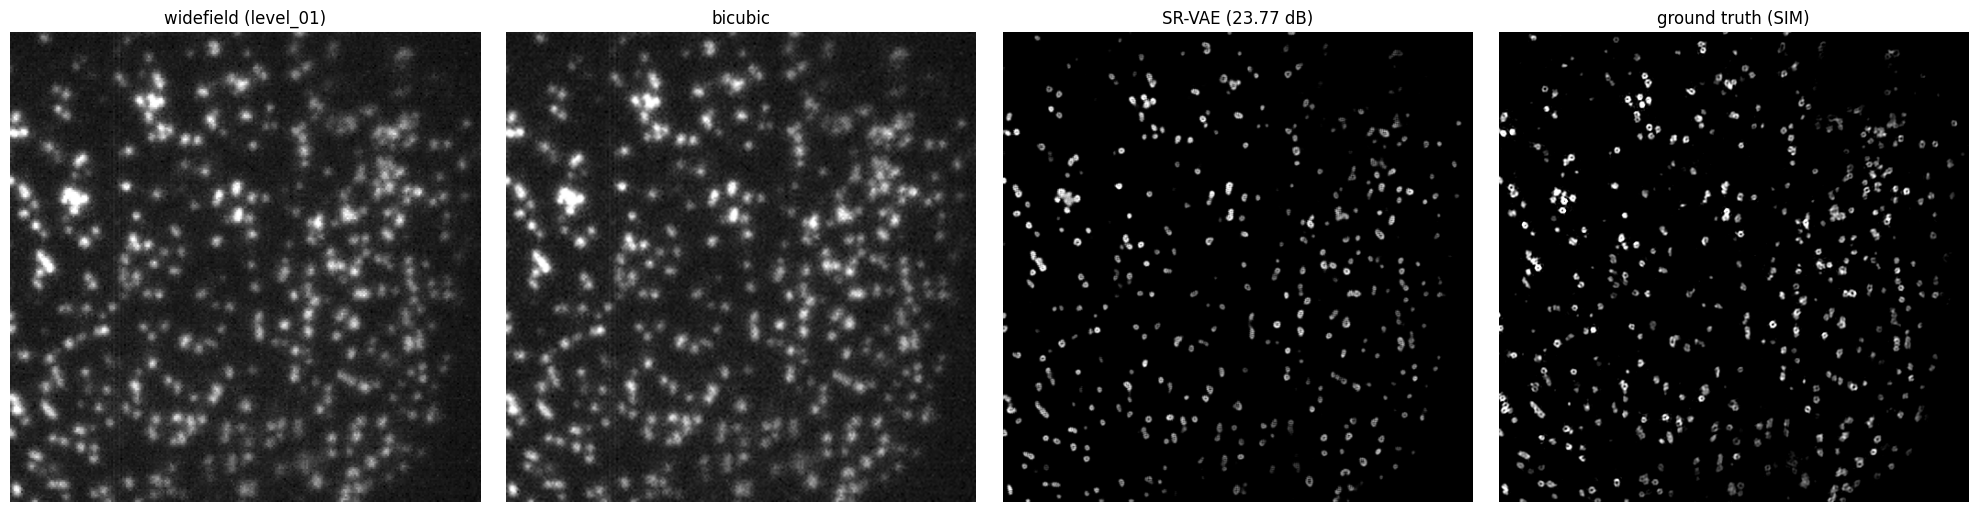

In [30]:
LEVEL_TO_SHOW = levels[0]     # change to any level folder name, e.g. levels[-1]
IMAGE_INDEX = 0               # 0 = first image (001)

pairs = LazyPairs(os.path.join(wf_root, LEVEL_TO_SHOW), gt_dir)
lr, gt = pairs[IMAGE_INDEX]
lr_t = torch.from_numpy(lr)[None, None].to(dev)
sr = sr_full(model, lr_t, TILE, OVERLAP)[0, 0].cpu().numpy()
bic = F.interpolate(lr_t, scale_factor=model.scale, mode="bicubic", align_corners=False).clamp(0, 1)[0, 0].cpu().numpy()

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a_, im, t in zip(ax, [lr, bic, sr, gt],
                     [f"widefield ({LEVEL_TO_SHOW})", "bicubic", f"SR-VAE ({psnr(sr, gt):.2f} dB)", "ground truth (SIM)"]):
    a_.imshow(im, cmap="gray"); a_.set_title(t); a_.axis("off")
plt.tight_layout(); plt.show()

## 9. Save the super-resolved images as .tif files (and open the folder in Windows Explorer)

Run this after the "Load the model" cell. Edit `OUT_DIR` / `SAVE_AS` at the top of the cell if you want.

In [31]:
# ============================================================================================
# SAVE the super-resolved images as .tif files and open the folder in Windows Explorer.
# Paste as a NEW cell in the TEST notebook, after the cell that loads the model
# (needs: model, dev, TEST_ROOT, TILE, OVERLAP, LazyPairs, sr_full - all defined in that notebook).
# Output layout:
#   sr_results/<level>/001_sr.tif, 002_sr.tif, ...        (+ 001_bicubic.tif ... if SAVE_EXTRAS)
#   sr_results/ground_truth/001.tif, ...                  (once, if SAVE_EXTRAS)
# ============================================================================================
import os, re
import numpy as np
import tifffile

OUT_DIR = "sr_results"        # created next to the notebook. Or a full path, e.g. r"C:\Users\BITPATNA\Desktop\sr_results"
SAVE_AS = "uint16"            # "uint16": opens in Windows Photos and ImageJ | "uint8": opens everywhere, less precise
                              # "float32": exact values, but Windows Photos/Explorer previews usually cannot show it (ImageJ can)
SAVE_EXTRAS = True            # also save bicubic and ground-truth images for side-by-side comparison
OPEN_EXPLORER = True          # open the output folder in Windows Explorer when finished


def to_saveable(img, how=SAVE_AS):
    """Model output is in [0, 1] (percentile-normalised units). Convert to the file's pixel type."""
    img = np.clip(img, 0.0, 1.0)
    if how == "uint16":
        return (img * 65535.0 + 0.5).astype(np.uint16)
    if how == "uint8":
        return (img * 255.0 + 0.5).astype(np.uint8)
    return img.astype(np.float32)


stem = lambda p: os.path.splitext(os.path.basename(p))[0]
natural = lambda s: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", s)]

gt_dir = os.path.join(TEST_ROOT, "test_gt")
wf_root = os.path.join(TEST_ROOT, "test_wf")
levels = sorted((d for d in os.listdir(wf_root) if os.path.isdir(os.path.join(wf_root, d))), key=natural)
os.makedirs(OUT_DIR, exist_ok=True)

n_saved = 0
for lv in levels:
    pairs = LazyPairs(os.path.join(wf_root, lv), gt_dir)
    lv_dir = os.path.join(OUT_DIR, lv)
    os.makedirs(lv_dir, exist_ok=True)
    for i, (wf_path, gt_path) in enumerate(pairs.files):
        lr, gt = pairs[i]
        lr_t = torch.from_numpy(lr)[None, None].to(dev)
        sr = sr_full(model, lr_t, TILE, OVERLAP)[0, 0].cpu().numpy()
        name = stem(wf_path)
        tifffile.imwrite(os.path.join(lv_dir, f"{name}_sr.tif"), to_saveable(sr))
        n_saved += 1
        if SAVE_EXTRAS:
            bic = F.interpolate(lr_t, scale_factor=model.scale, mode="bicubic",
                                align_corners=False).clamp(0, 1)[0, 0].cpu().numpy()
            tifffile.imwrite(os.path.join(lv_dir, f"{name}_bicubic.tif"), to_saveable(bic))
            gt_out = os.path.join(OUT_DIR, "ground_truth")
            os.makedirs(gt_out, exist_ok=True)
            if not os.path.exists(os.path.join(gt_out, f"{name}.tif")):
                tifffile.imwrite(os.path.join(gt_out, f"{name}.tif"), to_saveable(gt))
    print(f"{lv}: {len(pairs)} images saved")

print(f"done: {n_saved} super-resolved images -> {os.path.abspath(OUT_DIR)}")
if OPEN_EXPLORER and os.name == "nt":
    os.startfile(os.path.abspath(OUT_DIR))          # opens the folder in Windows Explorer

level_01: 15 images saved
level_02: 15 images saved
level_03: 15 images saved
level_04: 15 images saved
level_05: 15 images saved
level_06: 15 images saved
level_07: 15 images saved
level_08: 15 images saved
level_09: 15 images saved
done: 135 super-resolved images -> c:\Users\BITPATNA\Desktop\test_project\sr_results


In [32]:

import os
import csv
import torch
import torch.nn.functional as F
import numpy as np

from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

image_rows = []

model.eval()

for lv in levels:
    pairs = LazyPairs(os.path.join(wf_root, lv), gt_dir)

    for i, (lr, hr) in enumerate(pairs):
        # Convert LR image to tensor
        lr_t = torch.from_numpy(lr)[None, None].to(dev)

        # Generate SR-VAE prediction
        with torch.no_grad():
            sr = sr_full(model, lr_t, TILE, OVERLAP)[0, 0].cpu().numpy()

            # Bicubic baseline
            bic = F.interpolate(
                lr_t,
                scale_factor=model.scale,
                mode="bicubic",
                align_corners=False
            ).clamp(0, 1)[0, 0].cpu().numpy()

        # Calculate metrics for this individual image
        image_rows.append([
            lv,
            i + 1,
            psnr(sr, hr, data_range=1.0),
            ssim(sr, hr, data_range=1.0),
            psnr(bic, hr, data_range=1.0),
            ssim(bic, hr, data_range=1.0)
        ])

# Save individual image metrics
output_csv = "image_metrics_by_level.csv"

with open(output_csv, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "level",
        "image_index",
        "psnr_srvae",
        "ssim_srvae",
        "psnr_bicubic",
        "ssim_bicubic"
    ])
    writer.writerows(image_rows)

print(f"Saved {len(image_rows)} image-level results to {output_csv}")


KeyboardInterrupt: 